In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/revenue_at_risk.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_360.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_rfm_segments.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_ltv.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_rfm.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_risk.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_cohort_retention.csv


**Import Libraries**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


# Load All Analytical Datasets

In [3]:
import glob
import os

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("Files found:")
for file in files:
    print(file)

Files found:
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/revenue_at_risk.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_360.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_rfm_segments.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_ltv.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_rfm.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_risk.csv
/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_cohort_retention.csv


In [4]:
customer_360 = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_360.csv"
)

customer_rfm = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_rfm.csv"
)

customer_rfm_segments = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_rfm_segments.csv"
)

customer_ltv = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_ltv.csv"
)

customer_cohort_retention = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_cohort_retention.csv"
)

customer_risk = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/customer_risk.csv"
)

revenue_at_risk = pd.read_csv(
    "/kaggle/input/datasets/shrutimeshram29/e-commerce-customer-360-rfm-and-ltv-analytics/revenue_at_risk.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


# Data Understanding

In [5]:
datasets = {
    "Customer 360": customer_360,
    "Customer RFM": customer_rfm,
    "RFM Segments": customer_rfm_segments,
    "Customer LTV": customer_ltv,
    "Cohort Retention": customer_cohort_retention,
    "Customer Risk": customer_risk,
    "Revenue at Risk": revenue_at_risk
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customer 360: (3713, 11)
Customer RFM: (3713, 8)
RFM Segments: (3713, 9)
Customer LTV: (3713, 9)
Cohort Retention: (6, 6)
Customer Risk: (3713, 12)
Revenue at Risk: (6, 5)


In [6]:
customer_360.head()

,customer_id,first_purchase_date,last_purchase_date,transaction_count,total_revenue_usd,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views
0,6.743624e+07,2020-11-11,2020-11-11,1,48.0,48.0,46,2,0,1,13
1,3.827230e+06,2020-11-11,2020-11-11,1,71.0,71.0,72,7,0,1,21
2,1.699554e+07,2020-11-11,2020-11-11,1,19.0,19.0,47,3,0,1,13
3,6.759063e+06,2020-11-11,2020-11-11,1,14.0,14.0,73,1,0,1,25
4,2.474294e+06,2020-11-11,2020-11-11,1,1.0,1.0,50,3,0,1,16


In [7]:
customer_rfm.head()

,customer_id,recency_days,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_score
0,4.983866e+06,78,5,80.0,1,5,4,154
1,7.170660e+07,66,7,768.0,1,5,5,155
2,7.001373e+07,74,6,188.0,1,5,5,155
3,3.449027e+07,67,6,264.0,1,5,5,155
4,4.756779e+07,68,6,456.0,1,5,5,155


In [8]:
customer_ltv.head()

,customer_id,first_purchase_date,last_purchase_date,transaction_count,total_revenue_usd,avg_transaction_value,customer_lifespan_days,purchase_frequency_per_day,revenue_per_active_day
0,5.817048e+06,2020-11-17,2021-01-24,2,77.0,38.5,68,0.028986,1.115942
1,4.523775e+07,2020-11-28,2021-01-26,2,118.0,59.0,59,0.033333,1.966667
2,8.826088e+07,2020-11-18,2021-01-14,2,55.0,27.5,57,0.034483,0.948276
3,5.013172e+07,2020-11-30,2021-01-24,2,30.0,15.0,55,0.035714,0.535714
4,3.519863e+06,2020-11-30,2021-01-24,2,182.0,91.0,55,0.035714,3.250000


# Data Quality Checks

In [9]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(df.columns.tolist())


Customer 360
['customer_id', 'first_purchase_date', 'last_purchase_date', 'transaction_count', 'total_revenue_usd', 'avg_transaction_value', 'total_events', 'product_views', 'add_to_cart_events', 'checkout_events', 'page_views']

Customer RFM
['customer_id', 'recency_days', 'frequency', 'monetary', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_score']

RFM Segments
['customer_id', 'recency_days', 'frequency', 'monetary', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_score', 'customer_segment']

Customer LTV
['customer_id', 'first_purchase_date', 'last_purchase_date', 'transaction_count', 'total_revenue_usd', 'avg_transaction_value', 'customer_lifespan_days', 'purchase_frequency_per_day', 'revenue_per_active_day']

Cohort Retention
['cohort_month', 'activity_month', 'month_number', 'cohort_customers', 'active_customers', 'retention_rate']

Customer Risk
['customer_id', 'recency_days', 'frequency', 'monetary', 'recency_score', 'frequency_score', 'monetary_score

In [10]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(df.isnull().sum())


Customer 360
customer_id              0
first_purchase_date      0
last_purchase_date       0
transaction_count        0
total_revenue_usd        0
avg_transaction_value    0
total_events             0
product_views            0
add_to_cart_events       0
checkout_events          0
page_views               0
dtype: int64

Customer RFM
customer_id        0
recency_days       0
frequency          0
monetary           0
recency_score      0
frequency_score    0
monetary_score     0
rfm_score          0
dtype: int64

RFM Segments
customer_id         0
recency_days        0
frequency           0
monetary            0
recency_score       0
frequency_score     0
monetary_score      0
rfm_score           0
customer_segment    0
dtype: int64

Customer LTV
customer_id                   0
first_purchase_date           0
last_purchase_date            0
transaction_count             0
total_revenue_usd             0
avg_transaction_value         0
customer_lifespan_days        0
purchase_frequency

In [11]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Customer 360: 0 duplicate rows
Customer RFM: 0 duplicate rows
RFM Segments: 0 duplicate rows
Customer LTV: 0 duplicate rows
Cohort Retention: 0 duplicate rows
Customer Risk: 0 duplicate rows
Revenue at Risk: 0 duplicate rows


In [12]:
customer_360.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3713 entries, 0 to 3712
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            3713 non-null   float64
 1   first_purchase_date    3713 non-null   object 
 2   last_purchase_date     3713 non-null   object 
 3   transaction_count      3713 non-null   int64  
 4   total_revenue_usd      3713 non-null   float64
 5   avg_transaction_value  3713 non-null   float64
 6   total_events           3713 non-null   int64  
 7   product_views          3713 non-null   int64  
 8   add_to_cart_events     3713 non-null   int64  
 9   checkout_events        3713 non-null   int64  
 10  page_views             3713 non-null   int64  
dtypes: float64(3), int64(6), object(2)
memory usage: 319.2+ KB


In [13]:
customer_360.describe()

,customer_id,transaction_count,total_revenue_usd,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views
count,3.713000e+03,3713.000000,3713.000000,3713.000000,3713.000000,3713.000000,3713.000000,3713.000000,3713.000000
mean,2.731593e+08,1.202801,88.970644,75.577256,179.658228,23.025047,6.516025,5.697549,52.382709
std,1.213500e+09,0.776523,110.488055,87.174517,134.409901,24.225551,9.919657,5.129817,41.079314
min,1.016447e+06,1.000000,1.000000,1.000000,19.000000,0.000000,0.000000,1.000000,6.000000
25%,5.901522e+06,1.000000,31.000000,30.000000,85.000000,7.000000,0.000000,2.000000,24.000000
50%,2.416935e+07,1.000000,56.000000,52.000000,141.000000,16.000000,3.000000,4.000000,40.000000
75%,6.150689e+07,1.000000,101.000000,91.000000,233.000000,31.000000,8.000000,6.000000,67.000000
max,9.928813e+09,16.000000,1530.000000,1530.000000,1152.000000,330.000000,98.000000,66.000000,361.000000


# Customer 360 Analysis

In [14]:
total_customers = customer_360["customer_id"].nunique()
total_revenue = customer_360["total_revenue_usd"].sum()
avg_customer_revenue = customer_360["total_revenue_usd"].mean()
avg_transactions = customer_360["transaction_count"].mean()

print(f"Total Customers: {total_customers:,}")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Average Customer Revenue: ${avg_customer_revenue:,.2f}")
print(f"Average Transactions per Customer: {avg_transactions:.2f}")

Total Customers: 3,713
Total Revenue: $330,348.00
Average Customer Revenue: $88.97
Average Transactions per Customer: 1.20


In [15]:
print(f"Average Product Views: {customer_360['product_views'].mean():.2f}")
print(f"Average Add-to-Cart Events: {customer_360['add_to_cart_events'].mean():.2f}")
print(f"Average Checkout Events: {customer_360['checkout_events'].mean():.2f}")
print(f"Average Page Views: {customer_360['page_views'].mean():.2f}")

Average Product Views: 23.03
Average Add-to-Cart Events: 6.52
Average Checkout Events: 5.70
Average Page Views: 52.38


# Revenue Distribution

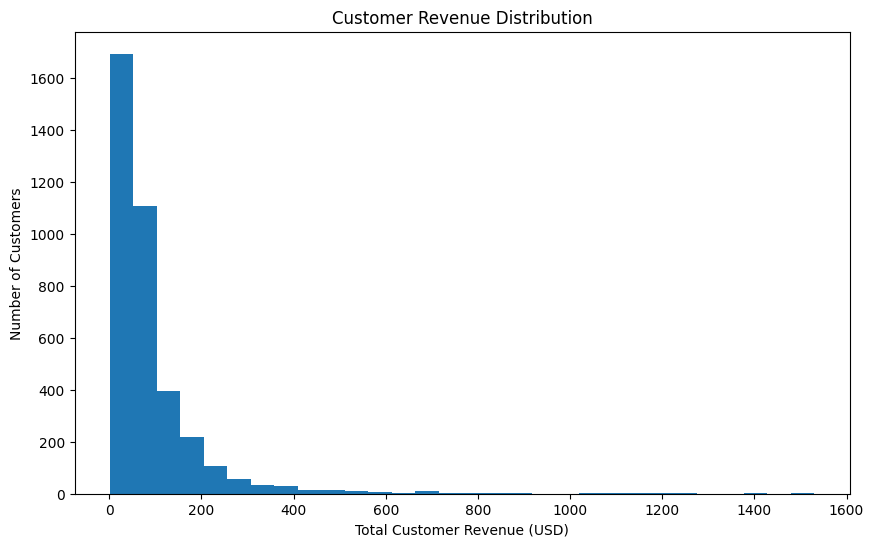

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(
    customer_360["total_revenue_usd"],
    bins=30
)

plt.title("Customer Revenue Distribution")
plt.xlabel("Total Customer Revenue (USD)")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
top_customers = (
    customer_360[
        ["customer_id", "transaction_count", "total_revenue_usd"]
    ]
    .sort_values("total_revenue_usd", ascending=False)
    .head(20)
)

top_customers

,customer_id,transaction_count,total_revenue_usd
3622,8.103644e+07,1,1530.0
3390,1.504653e+07,3,1424.0
3706,8.083450e+06,10,1404.0
3646,6.069512e+07,5,1260.0
3136,7.134559e+09,1,1200.0
1010,1.230643e+07,1,1170.0
3712,5.645226e+06,5,1121.0
2146,7.822143e+07,2,1049.0
371,4.147474e+07,1,904.0
1351,2.566419e+06,1,865.0


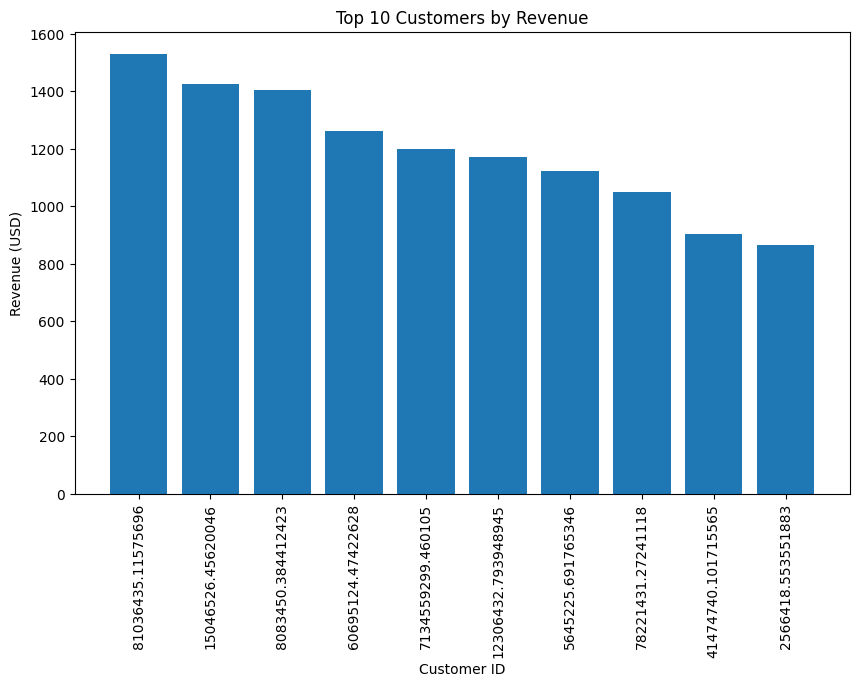

In [18]:
top_10 = (
    customer_360
    .sort_values("total_revenue_usd", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.bar(
    top_10["customer_id"].astype(str),
    top_10["total_revenue_usd"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=90)

plt.show()

# Transaction Behavior

In [19]:
transaction_distribution = (
    customer_360["transaction_count"]
    .value_counts()
    .sort_index()
)

transaction_distribution

transaction_count
1     3273
2      302
3       77
4       22
5       11
6       12
7        6
8        4
9        1
10       2
11       1
13       1
16       1
Name: count, dtype: int64

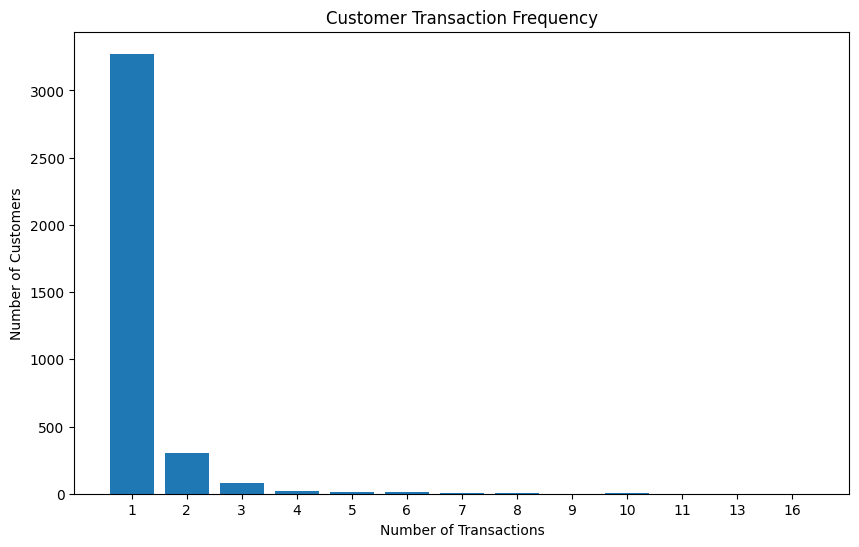

In [20]:
plt.figure(figsize=(10, 6))

plt.bar(
    transaction_distribution.index.astype(str),
    transaction_distribution.values
)

plt.title("Customer Transaction Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")

plt.show()

# RFM Analysis

In [21]:
customer_rfm.head()

,customer_id,recency_days,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_score
0,4.983866e+06,78,5,80.0,1,5,4,154
1,7.170660e+07,66,7,768.0,1,5,5,155
2,7.001373e+07,74,6,188.0,1,5,5,155
3,3.449027e+07,67,6,264.0,1,5,5,155
4,4.756779e+07,68,6,456.0,1,5,5,155


In [22]:
print("Recency Score:")
print(customer_rfm["recency_score"].value_counts().sort_index())

print("\nFrequency Score:")
print(customer_rfm["frequency_score"].value_counts().sort_index())

print("\nMonetary Score:")
print(customer_rfm["monetary_score"].value_counts().sort_index())

Recency Score:
recency_score
1    743
2    743
3    743
4    742
5    742
Name: count, dtype: int64

Frequency Score:
frequency_score
1    743
2    743
3    743
4    742
5    742
Name: count, dtype: int64

Monetary Score:
monetary_score
1    743
2    743
3    743
4    742
5    742
Name: count, dtype: int64


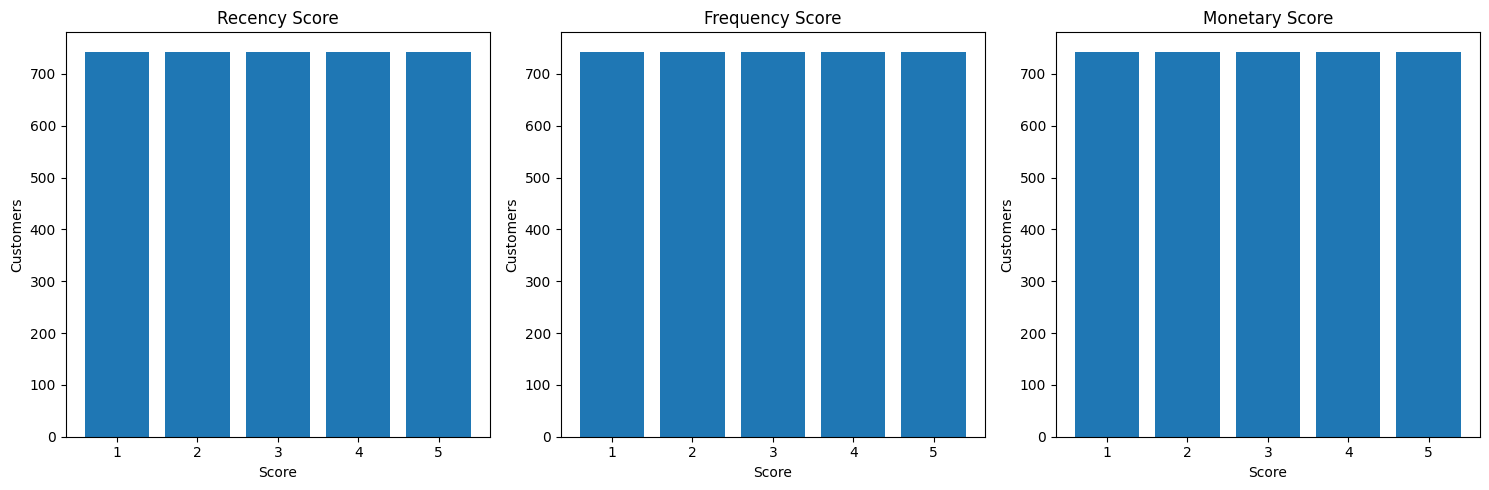

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].bar(
    customer_rfm["recency_score"].value_counts().sort_index().index,
    customer_rfm["recency_score"].value_counts().sort_index().values
)
axes[0].set_title("Recency Score")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Customers")

axes[1].bar(
    customer_rfm["frequency_score"].value_counts().sort_index().index,
    customer_rfm["frequency_score"].value_counts().sort_index().values
)
axes[1].set_title("Frequency Score")
axes[1].set_xlabel("Score")
axes[1].set_ylabel("Customers")

axes[2].bar(
    customer_rfm["monetary_score"].value_counts().sort_index().index,
    customer_rfm["monetary_score"].value_counts().sort_index().values
)
axes[2].set_title("Monetary Score")
axes[2].set_xlabel("Score")
axes[2].set_ylabel("Customers")

plt.tight_layout()
plt.show()

# RFM Segment Analysis

In [24]:
segment_summary = (
    customer_rfm_segments
    .groupby("customer_segment")
    .agg(
        customer_count=("customer_id", "count"),
        total_revenue=("monetary", "sum"),
        avg_revenue=("monetary", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

segment_summary

,customer_count,total_revenue,avg_revenue
customer_segment,,,
Hibernating / Lost,648,53777.0,82.989198
Champions,300,51948.0,173.160000
Loyal Customers,645,48899.0,75.812403
High Value At Risk,264,48748.0,184.651515
Other,562,41354.0,73.583630
Potential Loyalists,572,40041.0,70.001748
At Risk,574,35140.0,61.219512
New Customers,148,10441.0,70.547297


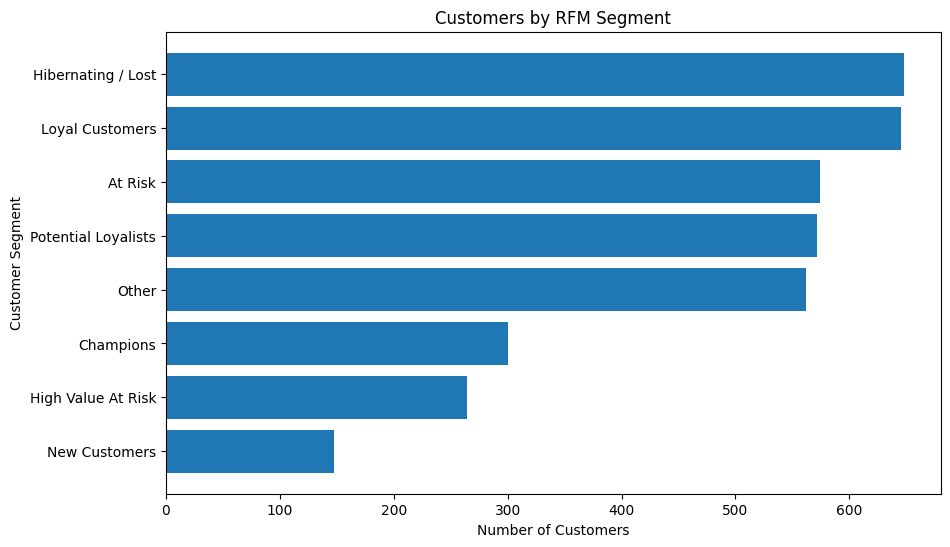

In [25]:
plt.figure(figsize=(10, 6))

segment_counts = (
    customer_rfm_segments["customer_segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.barh(
    segment_counts.index,
    segment_counts.values
)

plt.title("Customers by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.show()

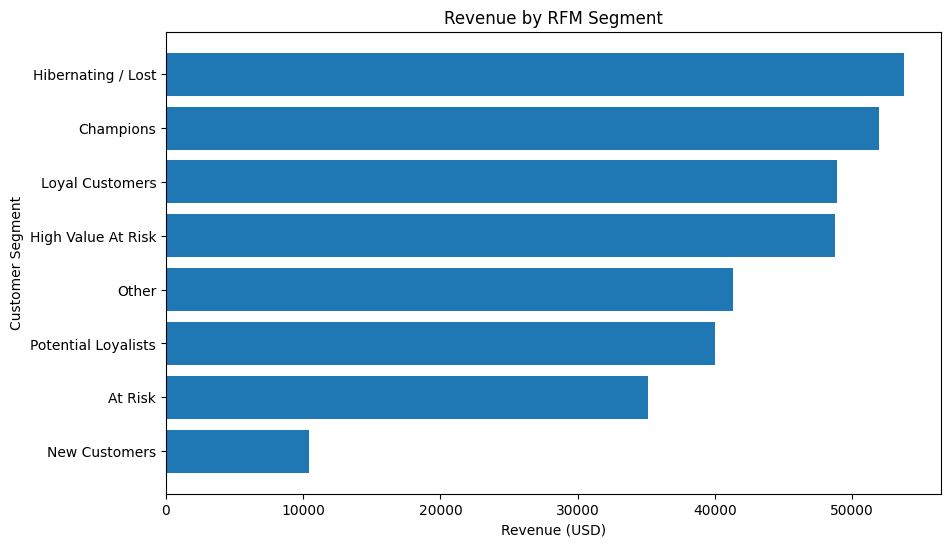

In [26]:
segment_revenue = (
    customer_rfm_segments
    .groupby("customer_segment")["monetary"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    segment_revenue.index,
    segment_revenue.values
)

plt.title("Revenue by RFM Segment")
plt.xlabel("Revenue (USD)")
plt.ylabel("Customer Segment")

plt.show()

# Customer Lifetime Value Analysis

In [27]:
customer_ltv.describe()

,customer_id,transaction_count,total_revenue_usd,avg_transaction_value,customer_lifespan_days,purchase_frequency_per_day,revenue_per_active_day
count,3.713000e+03,3713.000000,3713.000000,3713.000000,3713.000000,3713.000000,3713.000000
mean,2.731593e+08,1.202801,88.970644,75.577256,1.077565,1.050086,77.865054
std,1.213500e+09,0.776523,110.488055,87.174517,5.465942,0.589013,99.858353
min,1.016447e+06,1.000000,1.000000,1.000000,0.000000,0.028986,0.327273
25%,5.901522e+06,1.000000,31.000000,30.000000,0.000000,1.000000,27.000000
50%,2.416935e+07,1.000000,56.000000,52.000000,0.000000,1.000000,50.000000
75%,6.150689e+07,1.000000,101.000000,91.000000,0.000000,1.000000,92.000000
max,9.928813e+09,16.000000,1530.000000,1530.000000,68.000000,13.000000,1530.000000


In [28]:
print(f"Total Observed Revenue: ${customer_ltv['total_revenue_usd'].sum():,.2f}")
print(f"Average Historical LTV: ${customer_ltv['total_revenue_usd'].mean():,.2f}")
print(f"Average Customer Lifespan: {customer_ltv['customer_lifespan_days'].mean():.2f} days")
print(
    f"Average Purchase Frequency per Day: "
    f"{customer_ltv['purchase_frequency_per_day'].mean():.2f}"
)

Total Observed Revenue: $330,348.00
Average Historical LTV: $88.97
Average Customer Lifespan: 1.08 days
Average Purchase Frequency per Day: 1.05


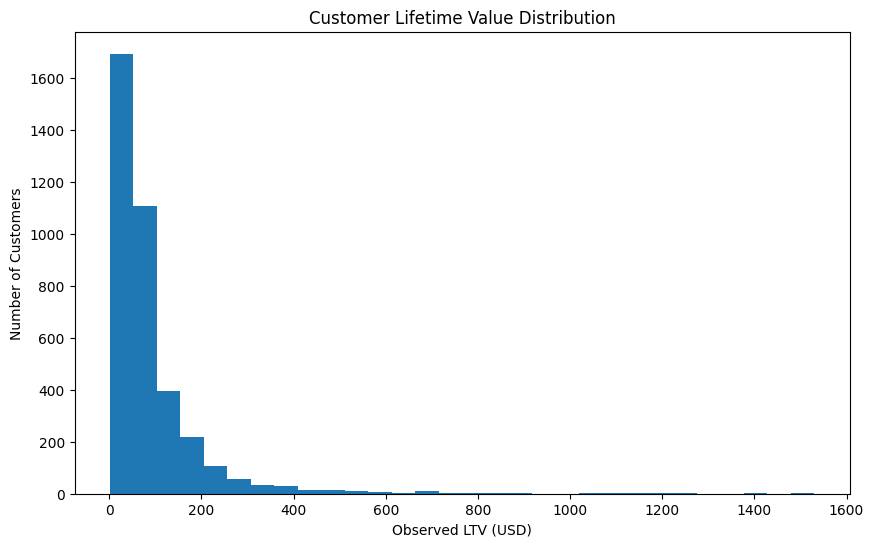

In [29]:
plt.figure(figsize=(10, 6))

plt.hist(
    customer_ltv["total_revenue_usd"],
    bins=30
)

plt.title("Customer Lifetime Value Distribution")
plt.xlabel("Observed LTV (USD)")
plt.ylabel("Number of Customers")

plt.show()

In [30]:
customer_ltv[
    [
        "customer_id",
        "transaction_count",
        "total_revenue_usd",
        "customer_lifespan_days"
    ]
].sort_values(
    "total_revenue_usd",
    ascending=False
).head(20)

,customer_id,transaction_count,total_revenue_usd,customer_lifespan_days
3511,8.103644e+07,1,1530.0,0
3683,1.504653e+07,3,1424.0,0
3711,8.083450e+06,10,1404.0,0
199,6.069512e+07,5,1260.0,8
3510,7.134559e+09,1,1200.0,0
3509,1.230643e+07,1,1170.0,0
3697,5.645226e+06,5,1121.0,0
33,7.822143e+07,2,1049.0,30
3508,4.147474e+07,1,904.0,0
3507,2.566419e+06,1,865.0,0


# Cohort Retention Analysis

In [31]:
customer_cohort_retention.head(20)

,cohort_month,activity_month,month_number,cohort_customers,active_customers,retention_rate
0,2020-11-01,2020-11-01,0,1113,1113,1.000000
1,2020-11-01,2020-12-01,1,1113,77,0.069182
2,2020-11-01,2021-01-01,2,1113,10,0.008985
3,2020-12-01,2020-12-01,0,1828,1828,1.000000
4,2020-12-01,2021-01-01,1,1828,37,0.020241
5,2021-01-01,2021-01-01,0,772,772,1.000000


In [32]:
customer_cohort_retention["cohort_month"] = pd.to_datetime(
    customer_cohort_retention["cohort_month"]
)

customer_cohort_retention["activity_month"] = pd.to_datetime(
    customer_cohort_retention["activity_month"]
)

customer_cohort_retention.head()

,cohort_month,activity_month,month_number,cohort_customers,active_customers,retention_rate
0,2020-11-01,2020-11-01,0,1113,1113,1.000000
1,2020-11-01,2020-12-01,1,1113,77,0.069182
2,2020-11-01,2021-01-01,2,1113,10,0.008985
3,2020-12-01,2020-12-01,0,1828,1828,1.000000
4,2020-12-01,2021-01-01,1,1828,37,0.020241


In [33]:
retention_matrix = customer_cohort_retention.pivot(
    index="cohort_month",
    columns="month_number",
    values="retention_rate"
)

retention_matrix

month_number,0,1,2
cohort_month,,,
2020-11-01,1.0,0.069182,0.008985
2020-12-01,1.0,0.020241,NaN
2021-01-01,1.0,NaN,NaN


In [34]:
retention_percentage = retention_matrix * 100

retention_percentage.round(2)

month_number,0,1,2
cohort_month,,,
2020-11-01,100.0,6.92,0.9
2020-12-01,100.0,2.02,NaN
2021-01-01,100.0,NaN,NaN


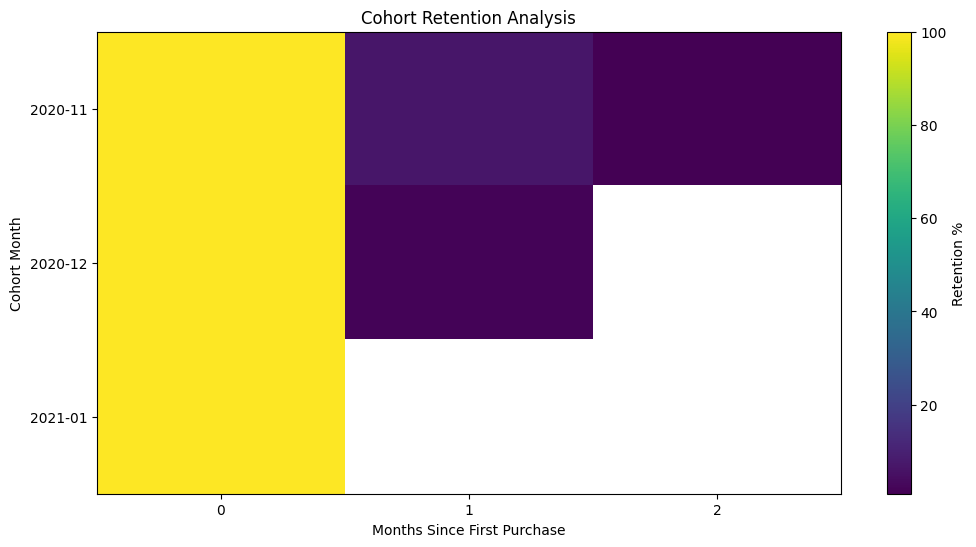

In [35]:
plt.figure(figsize=(12, 6))

plt.imshow(
    retention_percentage,
    aspect="auto"
)

plt.colorbar(label="Retention %")

plt.xticks(
    range(len(retention_percentage.columns)),
    retention_percentage.columns
)

plt.yticks(
    range(len(retention_percentage.index)),
    retention_percentage.index.strftime("%Y-%m")
)

plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort Month")
plt.title("Cohort Retention Analysis")

plt.show()

# Customer Risk Analysis

In [36]:
risk_summary = (
    customer_risk
    .groupby("risk_segment")
    .agg(
        customer_count=("customer_id", "count"),
        total_ltv=("ltv", "sum"),
        average_ltv=("ltv", "mean")
    )
    .sort_values("total_ltv", ascending=False)
)

risk_summary

,customer_count,total_ltv,average_ltv
risk_segment,,,
Other,1310,109629.0,83.686260
High Value At Risk,600,103353.0,172.255000
Champions,300,51948.0,173.160000
Loyal Customers,617,31106.0,50.414911
At Risk,467,18074.0,38.702355
Hibernating / Lost,419,16238.0,38.754177


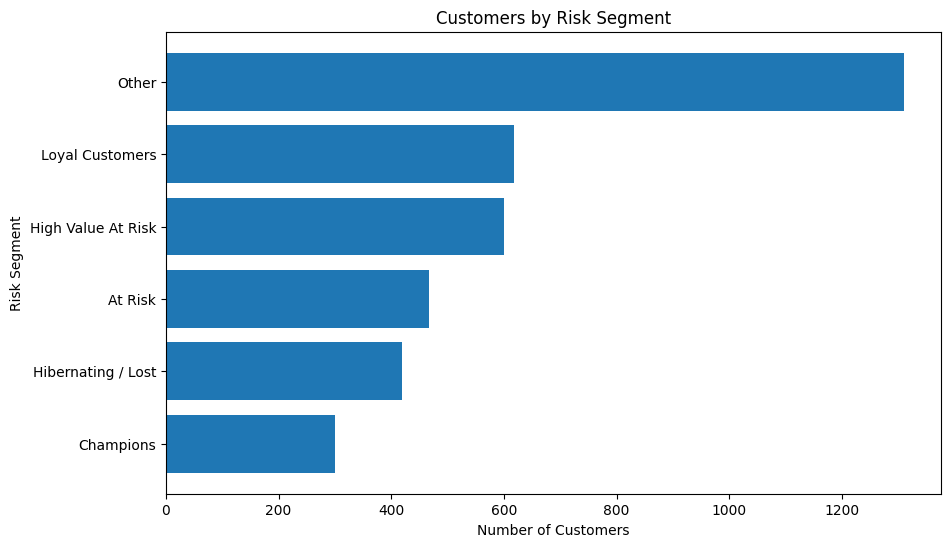

In [37]:
risk_counts = (
    customer_risk["risk_segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    risk_counts.index,
    risk_counts.values
)

plt.title("Customers by Risk Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Risk Segment")

plt.show()

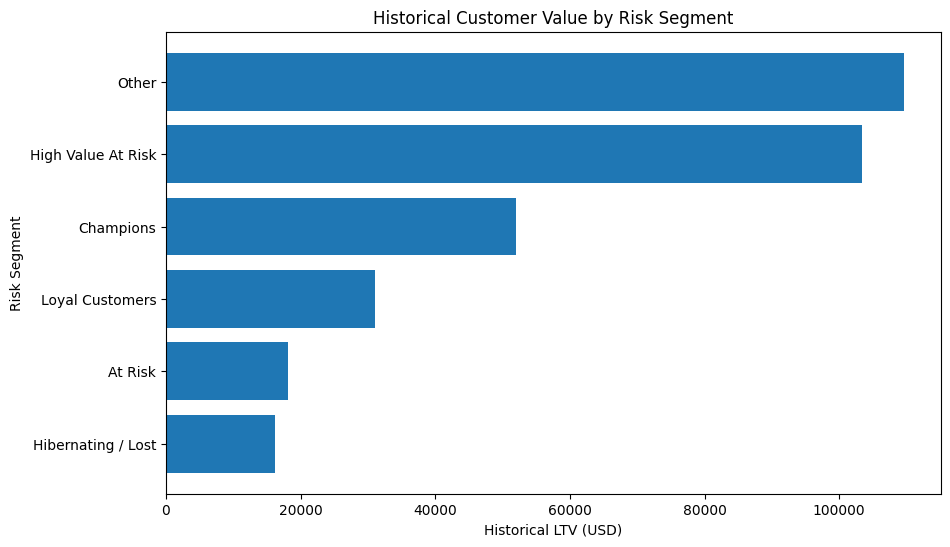

In [38]:
risk_ltv = (
    customer_risk
    .groupby("risk_segment")["ltv"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    risk_ltv.index,
    risk_ltv.values
)

plt.title("Historical Customer Value by Risk Segment")
plt.xlabel("Historical LTV (USD)")
plt.ylabel("Risk Segment")

plt.show()

# High-Value Customers at Risk

In [39]:
high_value_risk = customer_risk[
    customer_risk["risk_segment"] == "High Value At Risk"
].copy()

high_value_risk = high_value_risk.sort_values(
    "ltv",
    ascending=False
)

high_value_risk.head(20)

,customer_id,recency_days,frequency,monetary,recency_score,frequency_score,monetary_score,ltv,transaction_count,customer_lifespan_days,purchase_frequency_per_day,risk_segment
1867,1.230643e+07,78,1,1170.0,1,4,5,1170.0,1,0,1.0,High Value At Risk
1484,4.147474e+07,70,1,904.0,1,2,5,904.0,1,0,1.0,High Value At Risk
3112,3.938895e+07,65,1,806.0,1,1,5,806.0,1,0,1.0,High Value At Risk
1084,3.833172e+06,54,2,771.0,2,5,5,771.0,2,0,2.0,High Value At Risk
1236,7.170660e+07,66,7,768.0,1,5,5,768.0,7,0,7.0,High Value At Risk
300,6.317738e+07,61,4,744.0,2,5,5,744.0,4,0,4.0,High Value At Risk
306,7.019544e+06,72,1,708.0,1,1,5,708.0,1,0,1.0,High Value At Risk
1993,2.768703e+06,67,1,704.0,1,1,5,704.0,1,0,1.0,High Value At Risk
3117,1.314182e+07,71,1,680.0,1,2,5,680.0,1,0,1.0,High Value At Risk
676,2.606412e+07,71,1,678.0,1,3,5,678.0,1,0,1.0,High Value At Risk


In [40]:
print(
    f"High Value At Risk Customers: "
    f"{len(high_value_risk):,}"
)

print(
    f"Historical LTV of High Value At Risk Customers: "
    f"${high_value_risk['ltv'].sum():,.2f}"
)

print(
    f"Average LTV of High Value At Risk Customers: "
    f"${high_value_risk['ltv'].mean():,.2f}"
)

High Value At Risk Customers: 600
Historical LTV of High Value At Risk Customers: $103,353.00
Average LTV of High Value At Risk Customers: $172.25


# Revenue at Risk

In [41]:
revenue_at_risk

,risk_segment,customer_count,total_ltv,risk_factor,revenue_at_risk
0,Champions,300,51948.0,0.00,0.00
1,Loyal Customers,617,31106.0,0.00,0.00
2,Other,1310,109629.0,0.00,0.00
3,At Risk,467,18074.0,0.50,9037.00
4,Hibernating / Lost,419,16238.0,0.90,14614.20
5,High Value At Risk,600,103353.0,0.75,77514.75


In [42]:
total_revenue_at_risk = revenue_at_risk["revenue_at_risk"].sum()

print(
    f"Estimated Revenue at Risk: "
    f"${total_revenue_at_risk:,.2f}"
)

Estimated Revenue at Risk: $101,165.95


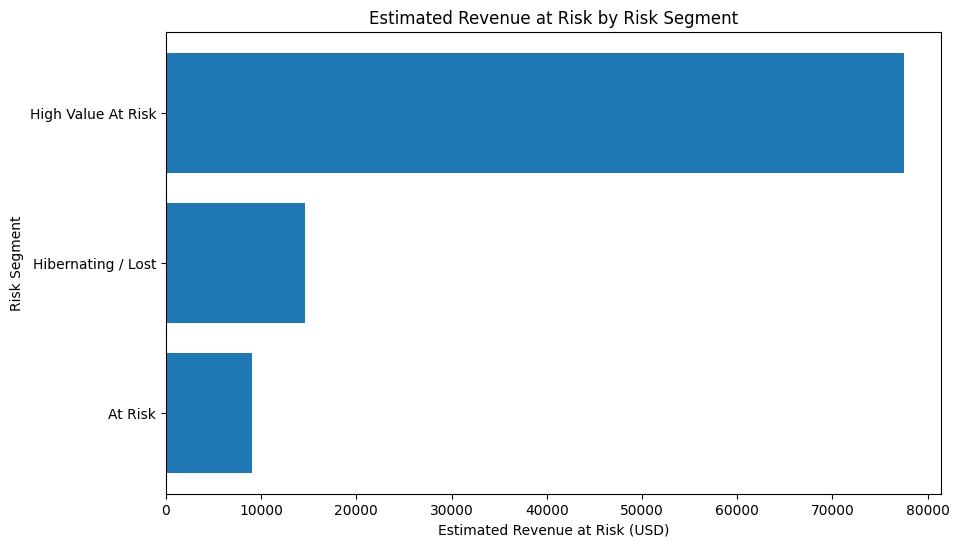

In [43]:
risk_revenue = (
    revenue_at_risk[
        revenue_at_risk["revenue_at_risk"] > 0
    ]
    .sort_values("revenue_at_risk")
)

plt.figure(figsize=(10, 6))

plt.barh(
    risk_revenue["risk_segment"],
    risk_revenue["revenue_at_risk"]
)

plt.title("Estimated Revenue at Risk by Risk Segment")
plt.xlabel("Estimated Revenue at Risk (USD)")
plt.ylabel("Risk Segment")

plt.show()

# Revenue-at-Risk Contribution

In [ ]:
revenue_at_risk["risk_contribution_pct"] = (
    revenue_at_risk["revenue_at_risk"]
    / revenue_at_risk["revenue_at_risk"].sum()
    * 100
)

revenue_at_risk.sort_values(
    "revenue_at_risk",
    ascending=False
)

# Key Business Insights

In [ ]:
largest_segment = (
    segment_summary["customer_count"]
    .idxmax()
)

largest_revenue_segment = (
    segment_summary["total_revenue"]
    .idxmax()
)

largest_risk_segment = (
    risk_summary["customer_count"]
    .idxmax()
)

largest_revenue_risk_segment = (
    revenue_at_risk
    .sort_values("revenue_at_risk", ascending=False)
    .iloc[0]["risk_segment"]
)

print("KEY BUSINESS INSIGHTS")
print("=" * 60)

print(
    f"1. Largest customer segment: "
    f"{largest_segment}"
)

print(
    f"2. Segment generating the highest revenue: "
    f"{largest_revenue_segment}"
)

print(
    f"3. Largest risk segment by customer count: "
    f"{largest_risk_segment}"
)

print(
    f"4. Largest contributor to estimated revenue at risk: "
    f"{largest_revenue_risk_segment}"
)

print(
    f"5. Total estimated revenue at risk: "
    f"${total_revenue_at_risk:,.2f}"
)

# Important Customer Metrics

In [ ]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Observed Revenue",
        "Average Customer Revenue",
        "Average Transactions per Customer",
        "Average Customer Lifespan",
        "High Value At Risk Customers",
        "Estimated Revenue at Risk"
    ],
    "Value": [
        f"{customer_360['customer_id'].nunique():,}",
        f"${customer_360['total_revenue_usd'].sum():,.2f}",
        f"${customer_360['total_revenue_usd'].mean():,.2f}",
        f"{customer_360['transaction_count'].mean():.2f}",
        f"{customer_ltv['customer_lifespan_days'].mean():.2f} days",
        f"{len(high_value_risk):,}",
        f"${total_revenue_at_risk:,.2f}"
    ]
})

kpi_summary

# Final Customer Risk Table

In [ ]:
final_risk_table = (
    customer_risk[
        [
            "customer_id",
            "risk_segment",
            "recency_days",
            "frequency",
            "monetary",
            "ltv"
        ]
    ]
    .sort_values("ltv", ascending=False)
)

final_risk_table.head(20)

# Export Important Python Outputs

In [ ]:
segment_summary.to_csv(
    "/kaggle/working/rfm_segment_summary.csv"
)

risk_summary.to_csv(
    "/kaggle/working/risk_segment_summary.csv"
)

high_value_risk.to_csv(
    "/kaggle/working/high_value_at_risk_customers.csv",
    index=False
)

kpi_summary.to_csv(
    "/kaggle/working/kpi_summary.csv",
    index=False
)

print("Analysis files exported successfully!")

# Final Project Summary

In [ ]:
print("""
E-COMMERCE CUSTOMER 360, RFM & LTV ANALYTICS
============================================

Data Layer:
BigQuery

Analysis:
Python + Pandas + NumPy

Visualization:
Matplotlib

Business Areas:
1. Customer 360
2. Customer behavior
3. RFM segmentation
4. Customer Lifetime Value
5. Cohort retention
6. Customer risk
7. Revenue at risk

Key Objective:
Identify customer segments, understand customer value,
analyze retention, identify high-value customers at risk,
and estimate historical revenue exposure using defined
risk assumptions.
""")

In [44]:
import pandas as pd
from pathlib import Path

# Find the uploaded ML files automatically
base_path = Path("/kaggle/input")

churn_path = list(base_path.rglob("ml_churn_dataset.csv"))[0]
ltv_path = list(base_path.rglob("ml_ltv_dataset.csv"))[0]
cluster_path = list(base_path.rglob("ml_customer_clusters.csv"))[0]

# Load datasets
churn_df = pd.read_csv(churn_path)
ltv_df = pd.read_csv(ltv_path)
cluster_df = pd.read_csv(cluster_path)

print("Files loaded successfully!")

print("\nCHURN DATASET")
print("Shape:", churn_df.shape)
display(churn_df.head())

print("\nLTV DATASET")
print("Shape:", ltv_df.shape)
display(ltv_df.head())

print("\nCLUSTER DATASET")
print("Shape:", cluster_df.shape)
display(cluster_df.head())

Files loaded successfully!

CHURN DATASET
Shape: (2953, 12)


,customer_id,recency_days,frequency,monetary,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views,shopping_events,inactive_30d
0,2.474294e+06,51,1,1.0,1.0,50,3,0,1,16,4,1
1,9.004034e+06,37,1,6.0,6.0,72,5,0,1,24,6,1
2,2.372140e+06,35,1,6.0,6.0,237,54,19,1,57,74,1
3,1.202924e+06,51,1,8.0,8.0,94,6,0,1,29,7,1
4,1.766357e+07,50,1,8.0,8.0,78,5,0,1,26,6,1



LTV DATASET
Shape: (2941, 11)


,customer_id,recency_days,frequency,historical_revenue,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views,future_30d_revenue
0,2.474294e+06,50,1,1.0,1.0,50,3,0,1,16,0.0
1,9.004034e+06,36,1,6.0,6.0,72,5,0,1,24,0.0
2,2.372140e+06,34,1,6.0,6.0,237,54,19,1,57,0.0
3,1.202924e+06,50,1,8.0,8.0,94,6,0,1,29,0.0
4,1.766357e+07,49,1,8.0,8.0,78,5,0,1,26,0.0



CLUSTER DATASET
Shape: (2941, 10)


,customer_id,recency_days,frequency,historical_revenue,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views
0,2.474294e+06,50,1,1.0,1.0,50,3,0,1,16
1,9.004034e+06,36,1,6.0,6.0,72,5,0,1,24
2,2.372140e+06,34,1,6.0,6.0,237,54,19,1,57
3,1.202924e+06,50,1,8.0,8.0,94,6,0,1,29
4,1.766357e+07,49,1,8.0,8.0,78,5,0,1,26


In [45]:
# Convert customer IDs to text
churn_df["customer_id"] = churn_df["customer_id"].astype(str)
ltv_df["customer_id"] = ltv_df["customer_id"].astype(str)
cluster_df["customer_id"] = cluster_df["customer_id"].astype(str)

print("===== CHURN DATASET =====")
print("Shape:", churn_df.shape)
print("\nMissing values:")
print(churn_df.isnull().sum())

print("\nTarget distribution:")
print(churn_df["inactive_30d"].value_counts())

print("\n===== LTV DATASET =====")
print("Shape:", ltv_df.shape)
print("\nMissing values:")
print(ltv_df.isnull().sum())

print("\n===== CLUSTER DATASET =====")
print("Shape:", cluster_df.shape)
print("\nMissing values:")
print(cluster_df.isnull().sum())

===== CHURN DATASET =====
Shape: (2953, 12)

Missing values:
customer_id              0
recency_days             0
frequency                0
monetary                 0
avg_transaction_value    0
total_events             0
product_views            0
add_to_cart_events       0
checkout_events          0
page_views               0
shopping_events          0
inactive_30d             0
dtype: int64

Target distribution:
inactive_30d
1    2600
0     353
Name: count, dtype: int64

===== LTV DATASET =====
Shape: (2941, 11)

Missing values:
customer_id              0
recency_days             0
frequency                0
historical_revenue       0
avg_transaction_value    0
total_events             0
product_views            0
add_to_cart_events       0
checkout_events          0
page_views               0
future_30d_revenue       0
dtype: int64

===== CLUSTER DATASET =====
Shape: (2941, 10)

Missing values:
customer_id              0
recency_days             0
frequency                0
histor

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features for churn prediction
features = [
    "recency_days",
    "frequency",
    "monetary",
    "avg_transaction_value",
    "total_events",
    "product_views",
    "add_to_cart_events",
    "checkout_events",
    "page_views",
    "shopping_events"
]

X = churn_df[features]
y = churn_df["inactive_30d"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training rows: 2362
Testing rows: 591

Training target distribution:
inactive_30d
1    2080
0     282
Name: count, dtype: int64

Testing target distribution:
inactive_30d
1    520
0     71
Name: count, dtype: int64


In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create Logistic Regression model
logistic_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Predictions
y_pred = logistic_model.predict(X_test_scaled)
y_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation
print("=== LOGISTIC REGRESSION ===")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC Score:")
print(round(roc_auc_score(y_test, y_probability), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

=== LOGISTIC REGRESSION ===

Classification Report:
              precision    recall  f1-score   support

           0       0.18      0.61      0.28        71
           1       0.92      0.62      0.74       520

    accuracy                           0.62       591
   macro avg       0.55      0.61      0.51       591
weighted avg       0.83      0.62      0.69       591

ROC-AUC Score:
0.6581

Confusion Matrix:
[[ 43  28]
 [197 323]]


In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)
rf_probability = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("=== RANDOM FOREST ===")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("ROC-AUC Score:")
print(round(roc_auc_score(y_test, rf_probability), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

=== RANDOM FOREST ===

Classification Report:
              precision    recall  f1-score   support

           0       0.21      0.23      0.22        71
           1       0.89      0.88      0.89       520

    accuracy                           0.80       591
   macro avg       0.55      0.55      0.55       591
weighted avg       0.81      0.80      0.81       591

ROC-AUC Score:
0.574

Confusion Matrix:
[[ 16  55]
 [ 61 459]]


In [49]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Calculate class imbalance ratio
scale_pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]

print("Scale Pos Weight:", round(scale_pos_weight, 2))

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test)
xgb_probability = xgb_model.predict_proba(X_test)[:, 1]

# Evaluation
print("\n=== XGBOOST ===")

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

print("ROC-AUC Score:")
print(round(roc_auc_score(y_test, xgb_probability), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

Scale Pos Weight: 0.14

=== XGBOOST ===

Classification Report:
              precision    recall  f1-score   support

           0       0.17      0.30      0.22        71
           1       0.89      0.81      0.85       520

    accuracy                           0.75       591
   macro avg       0.53      0.55      0.53       591
weighted avg       0.81      0.75      0.77       591

ROC-AUC Score:
0.5664

Confusion Matrix:
[[ 21  50]
 [100 420]]


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Precision_Inactive": [
        precision_score(y_test, y_pred, pos_label=1),
        precision_score(y_test, rf_pred, pos_label=1),
        precision_score(y_test, xgb_pred, pos_label=1)
    ],
    "Recall_Inactive": [
        recall_score(y_test, y_pred, pos_label=1),
        recall_score(y_test, rf_pred, pos_label=1),
        recall_score(y_test, xgb_pred, pos_label=1)
    ],
    "F1_Inactive": [
        f1_score(y_test, y_pred, pos_label=1),
        f1_score(y_test, rf_pred, pos_label=1),
        f1_score(y_test, xgb_pred, pos_label=1)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_probability),
        roc_auc_score(y_test, rf_probability),
        roc_auc_score(y_test, xgb_probability)
    ]
})

model_results = model_results.round(4)

display(model_results)

,Model,Accuracy,Precision_Inactive,Recall_Inactive,F1_Inactive,ROC_AUC
0,Logistic Regression,0.6193,0.9202,0.6212,0.7417,0.6581
1,Random Forest,0.8037,0.8930,0.8827,0.8878,0.5740
2,XGBoost,0.7462,0.8936,0.8077,0.8485,0.5664


In [51]:
# Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance["Importance"] = feature_importance["Importance"].round(4)

display(feature_importance)

,Feature,Importance
0,recency_days,0.2016
4,total_events,0.1324
8,page_views,0.1151
2,monetary,0.1117
3,avg_transaction_value,0.1078
5,product_views,0.1030
9,shopping_events,0.0998
6,add_to_cart_events,0.0618
7,checkout_events,0.0520
1,frequency,0.0151


In [52]:
# Create churn prediction output

churn_predictions = X_test.copy()

churn_predictions["actual_inactive_30d"] = y_test.values

churn_predictions["logistic_probability"] = y_probability

churn_predictions["random_forest_probability"] = rf_probability

churn_predictions["xgboost_probability"] = xgb_probability

# Use Random Forest probability for the business risk score
churn_predictions["churn_probability"] = rf_probability

# Create risk bands
churn_predictions["risk_band"] = pd.cut(
    churn_predictions["churn_probability"],
    bins=[0, 0.33, 0.66, 1],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

display(churn_predictions.head())

print("\nRisk Band Distribution:")
print(churn_predictions["risk_band"].value_counts())

,recency_days,frequency,monetary,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views,shopping_events,actual_inactive_30d,logistic_probability,random_forest_probability,xgboost_probability,churn_probability,risk_band
2049,28,1,46.0,46.0,118,12,0,6,34,18,0,0.594650,0.681422,0.646232,0.681422,High
808,48,1,92.0,92.0,52,1,0,2,15,3,1,0.769034,0.859690,0.806826,0.859690,High
46,35,1,30.0,30.0,56,2,3,1,15,6,1,0.674977,0.857811,0.864964,0.857811,High
1099,38,1,36.0,36.0,90,8,0,3,25,11,0,0.683159,0.814850,0.855065,0.814850,High
1293,45,1,13.0,13.0,53,5,0,4,14,9,1,0.773463,0.875137,0.887334,0.875137,High



Risk Band Distribution:
risk_band
High      324
Medium    263
Low         4
Name: count, dtype: int64


In [53]:
# Add customer IDs back to the prediction output
churn_predictions["customer_id"] = churn_df.loc[
    churn_predictions.index, "customer_id"
].values

# Move customer_id to the first column
cols = ["customer_id"] + [
    col for col in churn_predictions.columns
    if col != "customer_id"
]

churn_predictions = churn_predictions[cols]

display(churn_predictions.head())

,customer_id,recency_days,frequency,monetary,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views,shopping_events,actual_inactive_30d,logistic_probability,random_forest_probability,xgboost_probability,churn_probability,risk_band
2049,8806541.100090135,28,1,46.0,46.0,118,12,0,6,34,18,0,0.594650,0.681422,0.646232,0.681422,High
808,58202770.93525617,48,1,92.0,92.0,52,1,0,2,15,3,1,0.769034,0.859690,0.806826,0.859690,High
46,38358825.77628365,35,1,30.0,30.0,56,2,3,1,15,6,1,0.674977,0.857811,0.864964,0.857811,High
1099,24406398.94610988,38,1,36.0,36.0,90,8,0,3,25,11,0,0.683159,0.814850,0.855065,0.814850,High
1293,69422630.54243699,45,1,13.0,13.0,53,5,0,4,14,9,1,0.773463,0.875137,0.887334,0.875137,High


In [54]:
churn_predictions.to_csv(
    "/kaggle/working/churn_predictions.csv",
    index=False
)

print("Saved: /kaggle/working/churn_predictions.csv")

Saved: /kaggle/working/churn_predictions.csv


In [55]:
from sklearn.model_selection import train_test_split

# Features for LTV prediction
ltv_features = [
    "recency_days",
    "frequency",
    "historical_revenue",
    "avg_transaction_value",
    "total_events",
    "product_views",
    "add_to_cart_events",
    "checkout_events",
    "page_views"
]

X_ltv = ltv_df[ltv_features]
y_ltv = ltv_df["future_30d_revenue"]

# Train-test split
X_ltv_train, X_ltv_test, y_ltv_train, y_ltv_test = train_test_split(
    X_ltv,
    y_ltv,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_ltv_train.shape[0])
print("Testing rows:", X_ltv_test.shape[0])

print("\nTarget summary:")
print(y_ltv.describe())

print("\nCustomers with future revenue:")
print((y_ltv > 0).sum())

print("Customers with zero future revenue:")
print((y_ltv == 0).sum())

Training rows: 2352
Testing rows: 589

Target summary:
count    2941.000000
mean        1.057123
std        10.327666
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       276.000000
Name: future_30d_revenue, dtype: float64

Customers with future revenue:
47
Customers with zero future revenue:
2894


In [56]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Linear Regression model
linear_ltv = LinearRegression()

# Train
linear_ltv.fit(X_ltv_train, y_ltv_train)

# Predict
linear_ltv_pred = linear_ltv.predict(X_ltv_test)

# Prevent negative revenue predictions
linear_ltv_pred = np.maximum(linear_ltv_pred, 0)

# Evaluate
mae = mean_absolute_error(y_ltv_test, linear_ltv_pred)
rmse = np.sqrt(mean_squared_error(y_ltv_test, linear_ltv_pred))
r2 = r2_score(y_ltv_test, linear_ltv_pred)

print("=== LINEAR REGRESSION — LTV ===")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))

=== LINEAR REGRESSION — LTV ===
MAE : 2.2841
RMSE: 11.2687
R²  : 0.0033


In [57]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest regression model
rf_ltv = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train
rf_ltv.fit(X_ltv_train, y_ltv_train)

# Predict
rf_ltv_pred = rf_ltv.predict(X_ltv_test)

# Prevent negative predictions
rf_ltv_pred = np.maximum(rf_ltv_pred, 0)

# Evaluate
rf_mae = mean_absolute_error(y_ltv_test, rf_ltv_pred)
rf_rmse = np.sqrt(mean_squared_error(y_ltv_test, rf_ltv_pred))
rf_r2 = r2_score(y_ltv_test, rf_ltv_pred)

print("=== RANDOM FOREST — LTV ===")
print("MAE :", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R²  :", round(rf_r2, 4))

=== RANDOM FOREST — LTV ===
MAE : 2.4935
RMSE: 11.3677
R²  : -0.0143


In [58]:
from xgboost import XGBRegressor

# Create XGBoost regression model
xgb_ltv = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_ltv.fit(X_ltv_train, y_ltv_train)

# Predict
xgb_ltv_pred = xgb_ltv.predict(X_ltv_test)

# Prevent negative predictions
xgb_ltv_pred = np.maximum(xgb_ltv_pred, 0)

# Evaluate
xgb_ltv_mae = mean_absolute_error(y_ltv_test, xgb_ltv_pred)
xgb_ltv_rmse = np.sqrt(mean_squared_error(y_ltv_test, xgb_ltv_pred))
xgb_ltv_r2 = r2_score(y_ltv_test, xgb_ltv_pred)

print("=== XGBOOST — LTV ===")
print("MAE :", round(xgb_ltv_mae, 4))
print("RMSE:", round(xgb_ltv_rmse, 4))
print("R²  :", round(xgb_ltv_r2, 4))

=== XGBOOST — LTV ===
MAE : 2.6521
RMSE: 11.6038
R²  : -0.0568


In [59]:
ltv_model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        mae,
        rf_mae,
        xgb_ltv_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse,
        xgb_ltv_rmse
    ],
    "R2": [
        r2,
        rf_r2,
        xgb_ltv_r2
    ]
})

ltv_model_results = ltv_model_results.round(4)

display(ltv_model_results)

,Model,MAE,RMSE,R2
0,Linear Regression,2.2841,11.2687,0.0033
1,Random Forest,2.4935,11.3677,-0.0143
2,XGBoost,2.6521,11.6038,-0.0568


In [61]:
from pathlib import Path
import pandas as pd

base_path = Path("/kaggle/input")

rolling_ltv_path = list(base_path.rglob("ml_ltv_rolling_dataset.csv"))[0]

rolling_ltv_df = pd.read_csv(rolling_ltv_path)

print("Rolling LTV dataset loaded successfully!")
print("Shape:", rolling_ltv_df.shape)
print("\nColumns:")
print(rolling_ltv_df.columns.tolist())

Rolling LTV dataset loaded successfully!
Shape: (36507, 12)

Columns:
['customer_id', 'cutoff_date', 'recency_days', 'frequency', 'historical_revenue', 'avg_transaction_value', 'total_events', 'product_views', 'add_to_cart_events', 'checkout_events', 'page_views', 'future_30d_revenue']


In [62]:
print("Shape:", rolling_ltv_df.shape)

print("\nFirst 5 rows:")
display(rolling_ltv_df.head())

print("\nData types:")
print(rolling_ltv_df.dtypes)

print("\nMissing values:")
print(rolling_ltv_df.isnull().sum())

print("\nFuture 30-day revenue distribution:")
print(rolling_ltv_df["future_30d_revenue"].describe())

print("\nCustomers with future revenue > 0:")
print((rolling_ltv_df["future_30d_revenue"] > 0).sum())

print("\nCustomers with future revenue = 0:")
print((rolling_ltv_df["future_30d_revenue"] == 0).sum())

Shape: (36507, 12)

First 5 rows:


,customer_id,cutoff_date,recency_days,frequency,historical_revenue,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views,future_30d_revenue
0,5.268717e+07,2020-12-18,18,1,64.0,64.0,153,25,6,6,37,0.0
1,8.633002e+06,2020-12-24,14,2,67.0,33.5,286,62,23,4,70,0.0
2,9.101214e+06,2020-12-25,26,1,239.0,239.0,340,65,26,1,95,0.0
3,9.101214e+06,2020-12-28,29,1,239.0,239.0,340,65,26,1,95,0.0
4,2.752938e+07,2020-12-21,14,1,147.0,147.0,190,28,0,2,60,0.0



Data types:
customer_id              float64
cutoff_date               object
recency_days               int64
frequency                  int64
historical_revenue       float64
avg_transaction_value    float64
total_events               int64
product_views              int64
add_to_cart_events         int64
checkout_events            int64
page_views                 int64
future_30d_revenue       float64
dtype: object

Missing values:
customer_id              0
cutoff_date              0
recency_days             0
frequency                0
historical_revenue       0
avg_transaction_value    0
total_events             0
product_views            0
add_to_cart_events       0
checkout_events          0
page_views               0
future_30d_revenue       0
dtype: int64

Future 30-day revenue distribution:
count    36507.000000
mean         1.785767
std         15.370472
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        443.000000
Name: futu

In [63]:
# Prepare features and targets for the two-stage LTV model

import numpy as np

# Convert IDs/dates to appropriate types
rolling_ltv_df["customer_id"] = rolling_ltv_df["customer_id"].astype(str)
rolling_ltv_df["cutoff_date"] = pd.to_datetime(rolling_ltv_df["cutoff_date"])

# Features used for prediction
features = [
    "recency_days",
    "frequency",
    "historical_revenue",
    "avg_transaction_value",
    "total_events",
    "product_views",
    "add_to_cart_events",
    "checkout_events",
    "page_views"
]

X = rolling_ltv_df[features]

# Stage 1 target:
# 1 = customer generates revenue in next 30 days
# 0 = no future revenue
y_purchase = (rolling_ltv_df["future_30d_revenue"] > 0).astype(int)

# Stage 2 target:
# actual future revenue, only for customers with revenue > 0
positive_ltv_df = rolling_ltv_df[
    rolling_ltv_df["future_30d_revenue"] > 0
].copy()

X_positive = positive_ltv_df[features]
y_revenue = positive_ltv_df["future_30d_revenue"]

print("Features:", features)
print("\nStage 1 dataset:", X.shape)
print("Stage 1 positive cases:", y_purchase.sum())
print("Stage 1 negative cases:", (y_purchase == 0).sum())

print("\nStage 2 dataset:", X_positive.shape)
print("Stage 2 positive revenue cases:", len(y_revenue))
print("Average positive future revenue:", round(y_revenue.mean(), 2))
print("Maximum positive future revenue:", round(y_revenue.max(), 2))

Features: ['recency_days', 'frequency', 'historical_revenue', 'avg_transaction_value', 'total_events', 'product_views', 'add_to_cart_events', 'checkout_events', 'page_views']

Stage 1 dataset: (36507, 9)
Stage 1 positive cases: 879
Stage 1 negative cases: 35628

Stage 2 dataset: (879, 9)
Stage 2 positive revenue cases: 879
Average positive future revenue: 74.17
Maximum positive future revenue: 443.0


In [64]:
# Time-based train/test split
# Earlier cutoff dates = training
# Later cutoff dates = testing

unique_dates = sorted(rolling_ltv_df["cutoff_date"].unique())

# Use the first 80% of dates for training
split_index = int(len(unique_dates) * 0.8)

train_dates = unique_dates[:split_index]
test_dates = unique_dates[split_index:]

train_df = rolling_ltv_df[
    rolling_ltv_df["cutoff_date"].isin(train_dates)
].copy()

test_df = rolling_ltv_df[
    rolling_ltv_df["cutoff_date"].isin(test_dates)
].copy()

print("Training dates:", train_dates[0], "to", train_dates[-1])
print("Testing dates:", test_dates[0], "to", test_dates[-1])

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining positive cases:",
      (train_df["future_30d_revenue"] > 0).sum())

print("Testing positive cases:",
      (test_df["future_30d_revenue"] > 0).sum())

Training dates: 2020-12-15 00:00:00 to 2020-12-27 00:00:00
Testing dates: 2020-12-28 00:00:00 to 2020-12-31 00:00:00

Training rows: 28604
Testing rows: 7903

Training positive cases: 699
Testing positive cases: 180


In [65]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Features
X_train = train_df[features]
X_test = test_df[features]

# Target: 1 = future revenue, 0 = no future revenue
y_train = (train_df["future_30d_revenue"] > 0).astype(int)
y_test = (test_df["future_30d_revenue"] > 0).astype(int)

# Random Forest with class balancing
rf_ltv_classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_ltv_classifier.fit(X_train, y_train)

# Predict
purchase_probability = rf_ltv_classifier.predict_proba(X_test)[:, 1]
y_pred = (purchase_probability >= 0.5).astype(int)

# Evaluation
print("Stage 1 — Future Revenue Classification")
print("---------------------------------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, purchase_probability), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Stage 1 — Future Revenue Classification
---------------------------------------
Accuracy : 0.98
Precision: 0.5462
Recall   : 0.7222
F1 Score : 0.622
ROC-AUC  : 0.9234

Confusion Matrix:
[[7615  108]
 [  50  130]]


In [66]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Customers with positive future revenue in training period
positive_train_df = train_df[
    train_df["future_30d_revenue"] > 0
].copy()

X_train_reg = positive_train_df[features]
y_train_reg = positive_train_df["future_30d_revenue"]

# Random Forest Regressor
rf_ltv_regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train regression model
rf_ltv_regressor.fit(X_train_reg, y_train_reg)

print("Stage 2 — Revenue Regression Model")
print("-----------------------------------")
print("Training rows:", len(X_train_reg))
print("Average training revenue:", round(y_train_reg.mean(), 2))
print("Maximum training revenue:", round(y_train_reg.max(), 2))

Stage 2 — Revenue Regression Model
-----------------------------------
Training rows: 699
Average training revenue: 76.66
Maximum training revenue: 443.0


In [67]:
# Stage 2 evaluation on positive-revenue customers in the test period

positive_test_df = test_df[
    test_df["future_30d_revenue"] > 0
].copy()

X_test_reg = positive_test_df[features]
y_test_reg = positive_test_df["future_30d_revenue"]

# Predict revenue
revenue_prediction = rf_ltv_regressor.predict(X_test_reg)

# Evaluation metrics
mae = mean_absolute_error(y_test_reg, revenue_prediction)
rmse = np.sqrt(mean_squared_error(y_test_reg, revenue_prediction))
r2 = r2_score(y_test_reg, revenue_prediction)

print("Stage 2 — Revenue Regression Evaluation")
print("----------------------------------------")
print("Test positive-revenue customers:", len(y_test_reg))
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Stage 2 — Revenue Regression Evaluation
----------------------------------------
Test positive-revenue customers: 180
MAE : 16.03
RMSE: 25.11
R²  : 0.7709


In [68]:
# Combine Stage 1 and Stage 2
# Expected Revenue = Probability of Revenue × Predicted Revenue Amount

# Stage 1 probability for every test customer
test_purchase_probability = rf_ltv_classifier.predict_proba(
    test_df[features]
)[:, 1]

# Stage 2 predicted revenue for every test customer
test_revenue_amount = rf_ltv_regressor.predict(
    test_df[features]
)

# Final expected revenue
expected_revenue = (
    test_purchase_probability * test_revenue_amount
)

# Create results table
ltv_predictions = test_df[
    ["customer_id", "cutoff_date", "future_30d_revenue"]
].copy()

ltv_predictions["purchase_probability"] = test_purchase_probability
ltv_predictions["predicted_revenue_if_purchase"] = test_revenue_amount
ltv_predictions["expected_30d_revenue"] = expected_revenue

print("Final LTV prediction dataset created!")
print("\nRows:", len(ltv_predictions))

print("\nFirst 10 predictions:")
display(ltv_predictions.head(10))

print("\nTotal actual future revenue:",
      round(ltv_predictions["future_30d_revenue"].sum(), 2))

print("Total predicted expected revenue:",
      round(ltv_predictions["expected_30d_revenue"].sum(), 2))

Final LTV prediction dataset created!

Rows: 7903

First 10 predictions:


,customer_id,cutoff_date,future_30d_revenue,purchase_probability,predicted_revenue_if_purchase,expected_30d_revenue
3,9101213.906372858,2020-12-28,0.0,0.059290,237.587131,14.086548
6,52206227.13049421,2020-12-31,0.0,0.108491,119.340019,12.947286
14,3006717593.40397,2020-12-28,0.0,0.080592,79.772921,6.429092
16,88637248.0603138,2020-12-28,0.0,0.033357,86.711691,2.892469
18,11026237.66952913,2020-12-28,0.0,0.086420,108.226750,9.352990
28,3175490.802012392,2020-12-31,0.0,0.037103,249.196984,9.246077
33,1073768.8680631283,2020-12-28,0.0,0.014221,44.940233,0.639090
37,1773396.041947378,2020-12-28,0.0,0.124588,130.767939,16.292180
42,20672792.120383006,2020-12-28,0.0,0.160299,68.332700,10.953671
43,18844012.886722136,2020-12-30,0.0,0.118433,69.703758,8.255204



Total actual future revenue: 11609.0
Total predicted expected revenue: 84832.71


In [69]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual vs predicted expected revenue for ALL test customers
y_actual = ltv_predictions["future_30d_revenue"]
y_expected = ltv_predictions["expected_30d_revenue"]

final_mae = mean_absolute_error(y_actual, y_expected)
final_rmse = np.sqrt(mean_squared_error(y_actual, y_expected))
final_r2 = r2_score(y_actual, y_expected)

print("Final Two-Stage LTV Model — Overall Evaluation")
print("-----------------------------------------------")
print("MAE :", round(final_mae, 2))
print("RMSE:", round(final_rmse, 2))
print("R²  :", round(final_r2, 4))

print("\nActual total revenue   :", round(y_actual.sum(), 2))
print("Predicted total revenue:", round(y_expected.sum(), 2))

print("\nPrediction / Actual ratio:",
      round(y_expected.sum() / y_actual.sum(), 2))

Final Two-Stage LTV Model — Overall Evaluation
-----------------------------------------------
MAE : 10.47
RMSE: 14.76
R²  : -0.4031

Actual total revenue   : 11609.0
Predicted total revenue: 84832.71

Prediction / Actual ratio: 7.31


In [70]:
# Train a Random Forest without class balancing
# This gives probabilities that better reflect the actual revenue rate.

rf_ltv_calibrated = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_ltv_calibrated.fit(X_train, y_train)

# Predict probability on the test set
calibrated_probability = rf_ltv_calibrated.predict_proba(
    X_test
)[:, 1]

print("Actual test revenue rate:",
      round(y_test.mean(), 4))

print("Average predicted probability:",
      round(calibrated_probability.mean(), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, calibrated_probability), 4))

Actual test revenue rate: 0.0228
Average predicted probability: 0.0214
ROC-AUC: 0.9553


In [71]:
# Recalculate expected revenue using calibrated probabilities

ltv_predictions["calibrated_purchase_probability"] = calibrated_probability

ltv_predictions["expected_30d_revenue_calibrated"] = (
    ltv_predictions["calibrated_purchase_probability"]
    * ltv_predictions["predicted_revenue_if_purchase"]
)

# Evaluate the calibrated two-stage model
y_actual = ltv_predictions["future_30d_revenue"]
y_expected = ltv_predictions["expected_30d_revenue_calibrated"]

final_mae = mean_absolute_error(y_actual, y_expected)
final_rmse = np.sqrt(mean_squared_error(y_actual, y_expected))
final_r2 = r2_score(y_actual, y_expected)

print("Calibrated Two-Stage LTV Model")
print("--------------------------------")
print("MAE :", round(final_mae, 2))
print("RMSE:", round(final_rmse, 2))
print("R²  :", round(final_r2, 4))

print("\nActual total future revenue:",
      round(y_actual.sum(), 2))

print("Predicted total expected revenue:",
      round(y_expected.sum(), 2))

print("\nPrediction / Actual ratio:",
      round(y_expected.sum() / y_actual.sum(), 2))

Calibrated Two-Stage LTV Model
--------------------------------
MAE : 2.13
RMSE: 9.83
R²  : 0.3777

Actual total future revenue: 11609.0
Predicted total expected revenue: 12450.74

Prediction / Actual ratio: 1.07


In [72]:
# Create clean final LTV prediction dataset

final_ltv_predictions = test_df[
    ["customer_id", "cutoff_date",
     "recency_days", "frequency", "historical_revenue",
     "avg_transaction_value", "total_events",
     "product_views", "add_to_cart_events",
     "checkout_events", "page_views",
     "future_30d_revenue"]
].copy()

final_ltv_predictions["purchase_probability"] = calibrated_probability

final_ltv_predictions["predicted_revenue_if_purchase"] = (
    test_revenue_amount
)

final_ltv_predictions["expected_30d_revenue"] = (
    calibrated_probability * test_revenue_amount
)

print("Final LTV prediction dataset:")
print("Rows:", len(final_ltv_predictions))
print("Columns:", len(final_ltv_predictions.columns))

display(final_ltv_predictions.head(10))

Final LTV prediction dataset:
Rows: 7903
Columns: 15


,customer_id,cutoff_date,recency_days,frequency,historical_revenue,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views,future_30d_revenue,purchase_probability,predicted_revenue_if_purchase,expected_30d_revenue
3,9101213.906372858,2020-12-28,29,1,239.0,239.0,340,65,26,1,95,0.0,0.021105,237.587131,5.014248
6,52206227.13049421,2020-12-31,15,1,83.0,83.0,260,30,12,6,74,0.0,0.006098,119.340019,0.727777
14,3006717593.40397,2020-12-28,18,1,101.0,101.0,142,16,10,6,39,0.0,0.005324,79.772921,0.424679
16,88637248.0603138,2020-12-28,13,1,105.0,105.0,357,51,15,8,111,0.0,0.001978,86.711691,0.171513
18,11026237.66952913,2020-12-28,28,1,82.0,82.0,137,25,1,2,41,0.0,0.008762,108.226750,0.948319
28,3175490.802012392,2020-12-31,22,1,376.0,376.0,183,4,6,14,50,0.0,0.009823,249.196984,2.447912
33,1073768.8680631283,2020-12-28,25,1,57.0,57.0,704,89,26,14,228,0.0,0.004195,44.940233,0.188518
37,1773396.041947378,2020-12-28,13,1,81.0,81.0,198,30,0,8,59,0.0,0.009543,130.767939,1.247873
42,20672792.120383006,2020-12-28,23,1,145.0,145.0,153,15,8,2,49,0.0,0.012262,68.332700,0.837872
43,18844012.886722136,2020-12-30,16,1,57.0,57.0,88,19,7,2,22,0.0,0.007962,69.703758,0.555002


In [73]:
# Save final LTV predictions

output_path = "/kaggle/working/final_ltv_predictions.csv"

final_ltv_predictions.to_csv(output_path, index=False)

print("File saved successfully!")
print(output_path)

File saved successfully!
/kaggle/working/final_ltv_predictions.csv


In [74]:
print("Cluster dataset shape:", cluster_df.shape)

print("\nColumns:")
print(cluster_df.columns.tolist())

print("\nFirst 5 rows:")
display(cluster_df.head())

print("\nMissing values:")
print(cluster_df.isnull().sum())

Cluster dataset shape: (2941, 10)

Columns:
['customer_id', 'recency_days', 'frequency', 'historical_revenue', 'avg_transaction_value', 'total_events', 'product_views', 'add_to_cart_events', 'checkout_events', 'page_views']

First 5 rows:


,customer_id,recency_days,frequency,historical_revenue,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views
0,2474293.7483038474,50,1,1.0,1.0,50,3,0,1,16
1,9004033.50648322,36,1,6.0,6.0,72,5,0,1,24
2,2372140.230066936,34,1,6.0,6.0,237,54,19,1,57
3,1202924.297094448,50,1,8.0,8.0,94,6,0,1,29
4,17663569.122962937,49,1,8.0,8.0,78,5,0,1,26



Missing values:
customer_id              0
recency_days             0
frequency                0
historical_revenue       0
avg_transaction_value    0
total_events             0
product_views            0
add_to_cart_events       0
checkout_events          0
page_views               0
dtype: int64


In [75]:
from sklearn.preprocessing import StandardScaler

# Features for customer clustering
cluster_features = [
    "recency_days",
    "frequency",
    "historical_revenue",
    "avg_transaction_value",
    "total_events",
    "product_views",
    "add_to_cart_events",
    "checkout_events",
    "page_views"
]

# Create feature matrix
X_cluster = cluster_df[cluster_features].copy()

# Scale the features so large-value columns don't dominate
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Clustering features:", len(cluster_features))
print("Scaled data shape:", X_cluster_scaled.shape)
print("Scaling completed successfully!")

Clustering features: 9
Scaled data shape: (2941, 9)
Scaling completed successfully!


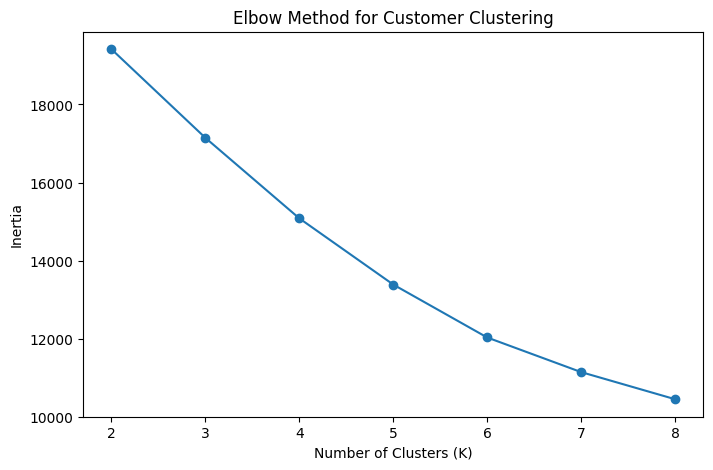

In [76]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_cluster_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Clustering")
plt.xticks(k_values)
plt.show()

In [77]:
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_cluster_scaled)
    
    score = silhouette_score(X_cluster_scaled, labels)
    silhouette_scores[k] = score

print("Silhouette Scores:")
for k, score in silhouette_scores.items():
    print(f"K = {k}: {score:.4f}")

Silhouette Scores:
K = 2: 0.4455
K = 3: 0.4369
K = 4: 0.2822
K = 5: 0.2084
K = 6: 0.2100
K = 7: 0.2201
K = 8: 0.2227


In [78]:
# Build final K-Means model with K = 2

kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_cluster_scaled)

# Add cluster labels to the customer dataset
cluster_results = cluster_df.copy()
cluster_results["cluster"] = cluster_labels

print("K-Means clustering completed!")
print("\nCustomers in each cluster:")
print(cluster_results["cluster"].value_counts().sort_index())

K-Means clustering completed!

Customers in each cluster:
cluster
0    2333
1     608
Name: count, dtype: int64


In [79]:
cluster_profile = cluster_results.groupby("cluster")[cluster_features].mean().round(2)

print("Customer Cluster Profile:")
display(cluster_profile)

Customer Cluster Profile:


,recency_days,frequency,historical_revenue,avg_transaction_value,total_events,product_views,add_to_cart_events,checkout_events,page_views
cluster,,,,,,,,,
0,26.70,1.08,67.45,63.22,127.66,14.43,4.09,4.14,36.99
1,21.69,1.74,190.18,135.30,373.61,55.67,15.05,9.63,109.35


In [80]:
# Give the clusters business-friendly names

cluster_name_map = {
    0: "Lower-Value / Lower-Engagement",
    1: "High-Value / Highly Engaged"
}

cluster_results["cluster_name"] = (
    cluster_results["cluster"].map(cluster_name_map)
)

print("Cluster names assigned successfully!")

print("\nCustomer count by cluster:")
print(
    cluster_results["cluster_name"]
    .value_counts()
)

Cluster names assigned successfully!

Customer count by cluster:
cluster_name
Lower-Value / Lower-Engagement    2333
High-Value / Highly Engaged        608
Name: count, dtype: int64


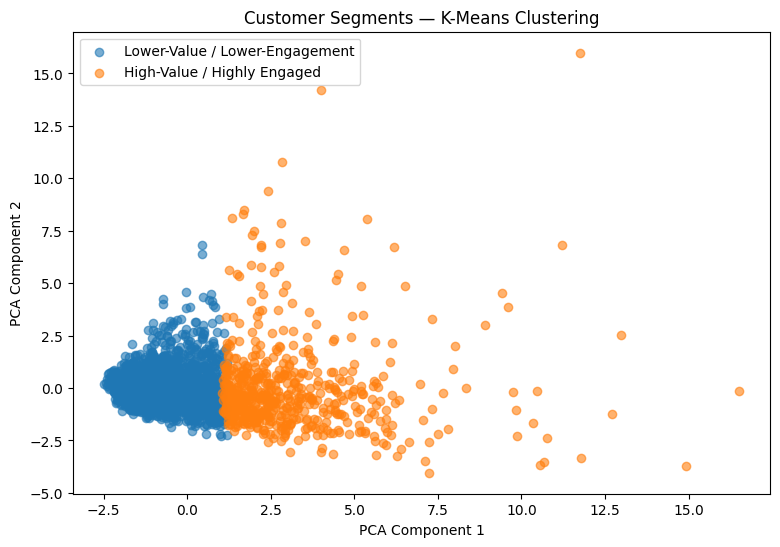

Variance explained by the two PCA components: 61.41 %


In [81]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce 9 clustering features to 2 dimensions
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_cluster_scaled)

# Plot clusters
plt.figure(figsize=(9, 6))

for cluster_id in sorted(cluster_results["cluster"].unique()):
    mask = cluster_results["cluster"] == cluster_id
    
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=cluster_name_map[cluster_id],
        alpha=0.6
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Customer Segments — K-Means Clustering")
plt.legend()
plt.show()

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [82]:
# Save final customer clustering results

final_cluster_output = cluster_results.copy()

output_path = "/kaggle/working/final_customer_clusters.csv"

final_cluster_output.to_csv(
    output_path,
    index=False
)

print("Final clustering file saved successfully!")
print(output_path)

print("\nRows:", len(final_cluster_output))
print("Columns:", len(final_cluster_output.columns))

Final clustering file saved successfully!
/kaggle/working/final_customer_clusters.csv

Rows: 2941
Columns: 12


In [83]:
import pandas as pd
from pathlib import Path

work_path = Path("/kaggle/working")

churn_predictions = pd.read_csv(
    work_path / "churn_predictions.csv"
)

final_ltv_predictions = pd.read_csv(
    work_path / "final_ltv_predictions.csv"
)

final_customer_clusters = pd.read_csv(
    work_path / "final_customer_clusters.csv"
)

print("All three ML outputs loaded successfully!")

print("\nChurn predictions:", churn_predictions.shape)
print("LTV predictions:", final_ltv_predictions.shape)
print("Customer clusters:", final_customer_clusters.shape)

All three ML outputs loaded successfully!

Churn predictions: (591, 17)
LTV predictions: (7903, 15)
Customer clusters: (2941, 12)


In [84]:
ml_summary = pd.DataFrame({
    "Model": [
        "Churn Classification",
        "LTV Revenue Classification",
        "LTV Revenue Regression",
        "Customer Clustering"
    ],
    "Technique": [
        "Random Forest",
        "Random Forest",
        "Random Forest",
        "K-Means"
    ],
    "Primary_Metric": [
        "ROC-AUC",
        "ROC-AUC",
        "R²",
        "Silhouette Score"
    ],
    "Score": [
        0.5740,
        0.9553,
        0.7709,
        0.4455
    ]
})

print("ML Model Summary")
display(ml_summary)

ML Model Summary


,Model,Technique,Primary_Metric,Score
0,Churn Classification,Random Forest,ROC-AUC,0.5740
1,LTV Revenue Classification,Random Forest,ROC-AUC,0.9553
2,LTV Revenue Regression,Random Forest,R²,0.7709
3,Customer Clustering,K-Means,Silhouette Score,0.4455


In [85]:
business_insights = pd.DataFrame({
    "Area": [
        "Customer Base",
        "Revenue",
        "Revenue at Risk",
        "High-Value Risk",
        "RFM Champions",
        "Customer Clustering",
        "Future Revenue Prediction",
        "Cohort Retention"
    ],
    "Key_Finding": [
        "3,713 customers generated valid transaction revenue",
        "$330,348 total observed revenue",
        "$101,165.95 estimated revenue at risk",
        "600 customers classified as High Value At Risk",
        "300 Champions generated $51,948 revenue",
        "608 customers are High-Value / Highly Engaged",
        "Calibrated two-stage model predicted $12,450.74 vs $11,609 actual future revenue",
        "November cohort retained 6.92% in Month 1 and 0.90% in Month 2"
    ]
})

print("Business Insights Summary")
display(business_insights)

Business Insights Summary


,Area,Key_Finding
0,Customer Base,"3,713 customers generated valid transaction re..."
1,Revenue,"$330,348 total observed revenue"
2,Revenue at Risk,"$101,165.95 estimated revenue at risk"
3,High-Value Risk,600 customers classified as High Value At Risk
4,RFM Champions,"300 Champions generated $51,948 revenue"
5,Customer Clustering,608 customers are High-Value / Highly Engaged
6,Future Revenue Prediction,"Calibrated two-stage model predicted $12,450.7..."
7,Cohort Retention,November cohort retained 6.92% in Month 1 and ...


In [86]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'final_customer_clusters.csv', 'final_ltv_predictions.csv', 'churn_predictions.csv']
